In [14]:
from pathlib import Path
from xml.etree import ElementTree as ET

import pandas as pd
import seaborn as sns
from pydantic import BaseModel
from sklearn.model_selection import GroupShuffleSplit

notebook_dir = Path.cwd()

PATHS = {
    "train": notebook_dir.parent / "data" / "raw" / "AR_Hotels_Train_SB1.xml",
    "test": notebook_dir.parent / "data" / "raw" / "AR_HOTE_SB1_TEST.xml.gold",
}

In [15]:
class Opinion(BaseModel):
    target: str | None = None
    category: str
    polarity: str


def parse(paths: dict[str, str]) -> pd.DataFrame:
    
    rows, sentence_id = [], 0
    for split, path in paths.items():
        for review in ET.parse(path).getroot().iter("Review"):
            for s in review.iter("sentence"):
                sentence_id += 1
                base = {"split": split, "review_id": int(review.get("rid")),
                        "sentence_id": sentence_id, "text": s.findtext("text")}
                opinions = [Opinion(**o.attrib).model_dump() for o in s.iter("Opinion")] or [{}]
                rows += [base | o for o in opinions]
    df = pd.DataFrame(rows)
    df[["entity", "attribute"]] = df.category.str.split("#", expand=True)
    return df


df = parse(PATHS)
df.head()

,split,review_id,sentence_id,text,target,category,polarity,entity,attribute
0,train,456,1,أنصح بالنوم وليس تناول الطعام موقع مثالي للإق...,موقع,LOCATION#GENERAL,positive,LOCATION,GENERAL
1,train,456,2,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,الغرفة,ROOMS#GENERAL,positive,ROOMS,GENERAL
2,train,456,2,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,الموظفون,SERVICE#GENERAL,positive,SERVICE,GENERAL
3,train,456,2,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,بوفيه الإفطار,FOOD_DRINKS#QUALITY,positive,FOOD_DRINKS,QUALITY
4,train,456,2,كانت الغرفة ممتازة وكذلك الموظفون وبوفيه الإفط...,وجبة العشاء,FOOD_DRINKS#PRICES,negative,FOOD_DRINKS,PRICES


In [16]:
ops = df.dropna(subset=["category"])          # opinions only
sents = df.drop_duplicates("sentence_id")     # one row per sentence, including empty ones

In [17]:
summary = df.groupby("split").agg(reviews=("review_id", "nunique"),
                                  sentences=("sentence_id", "nunique"),
                                  opinions=("category", "count"))
summary["no_opinion"] = df[df.category.isna()].groupby("split").size()
summary   

,reviews,sentences,opinions,no_opinion
split,,,,
test,452,1227,2604,2
train,1839,4802,10509,12


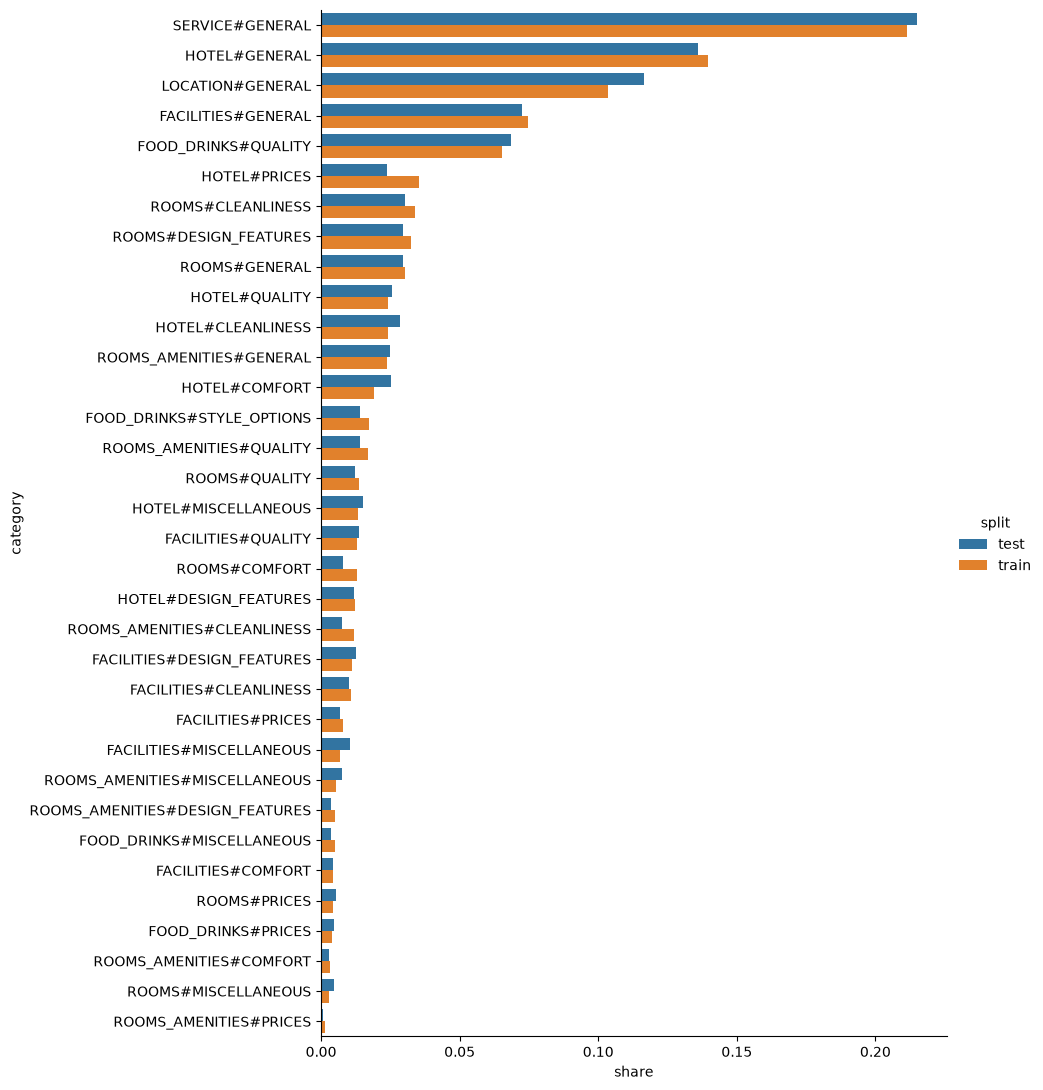

In [18]:
share = ops.groupby("split").category.value_counts(normalize=True).rename("share").reset_index()
order = ops[ops.split == "train"].category.value_counts().index
sns.catplot(data=share, y="category", x="share", hue="split", kind="bar",
            order=order, height=11, aspect=0.9);

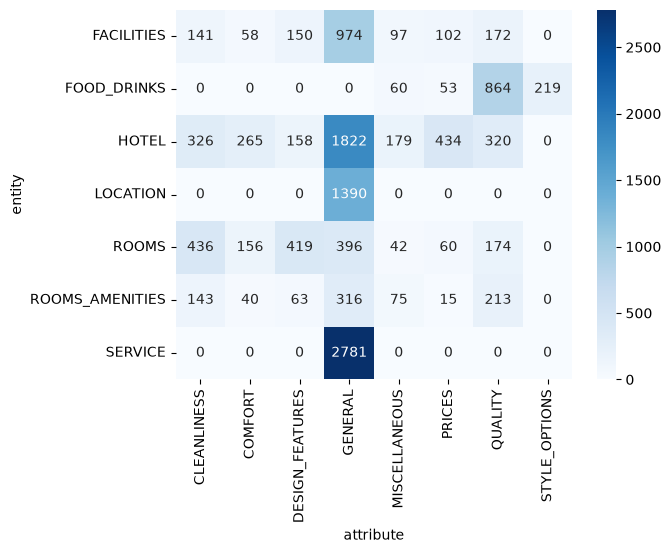

In [19]:
sns.heatmap(pd.crosstab(ops.entity, ops.attribute), annot=True, fmt="d", cmap="Blues");

In [20]:
counts = ops[ops.split == "train"].category.value_counts()
examples = (ops[ops.split == "train"].groupby("category").sample(1, random_state=0)
            .assign(n=lambda d: d.category.map(counts), text=lambda d: d.text.str[:80])
            .sort_values("n", ascending=False))
examples[["category", "n", "polarity", "target", "text"]].reset_index(drop=True)

,category,n,polarity,target,text
0,SERVICE#GENERAL,2221,positive,NULL,أحب أن أبدي أعجابي بالأقامه في الفندق و الخدما...
1,HOTEL#GENERAL,1468,positive,NULL,جيد إنه كان جيداً إلى حد ما وافضل من الباقين
2,LOCATION#GENERAL,1087,positive,الموقع,لقد وجدنًا الموقع هادئًا رغم وقوعه قُبالة الشا...
3,FACILITIES#GENERAL,785,positive,مطعم,هذا هو اختيار جيد جدا في منطقة سفاجا. لطيف جدا...
4,FOOD_DRINKS#QUALITY,686,negative,وجبة الإفطار,كما أنني لم أجروء على السماح لأطفالي بتناول ما...
5,HOTEL#PRICES,372,positive,موقع,قيمة جيدة للمال وموقع ممتاز
6,ROOMS#CLEANLINESS,357,positive,الغرف,والغرف كانت نظيفة ورائعة وتطل على الحرم النبوي...
7,ROOMS#DESIGN_FEATURES,342,negative,الغرف,صغر حجم الغرف باختصار الفندق لا يستحق خمس نجوم...
8,ROOMS#GENERAL,319,negative,غرفتي,على الجانب الخاطئ من المسجد ليست هذه هي المعاي...
9,HOTEL#QUALITY,253,negative,فندق,فندق سيئ للغاية ذهبت للفندق لمدة ليلة واحدة فق...


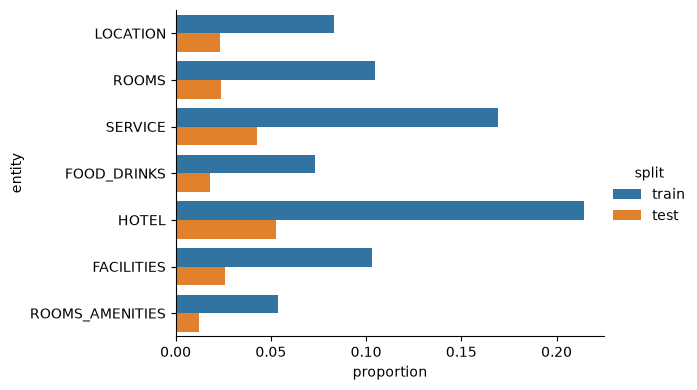

In [21]:
sns.catplot(data=ops, y="entity", hue="split", kind="count", stat="proportion", height=4, aspect=1.6);

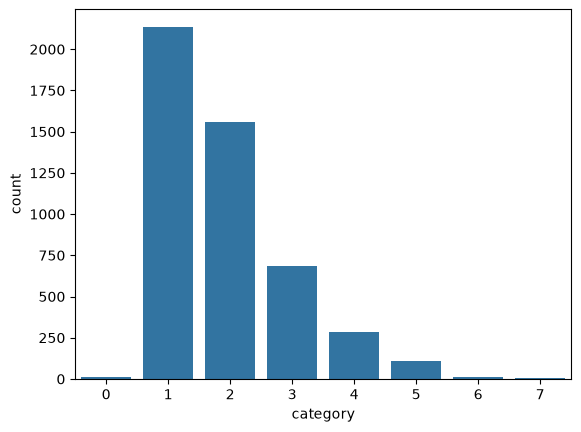

In [22]:
n_aspects = df[df.split == "train"].groupby("sentence_id").category.nunique()
sns.countplot(x=n_aspects);

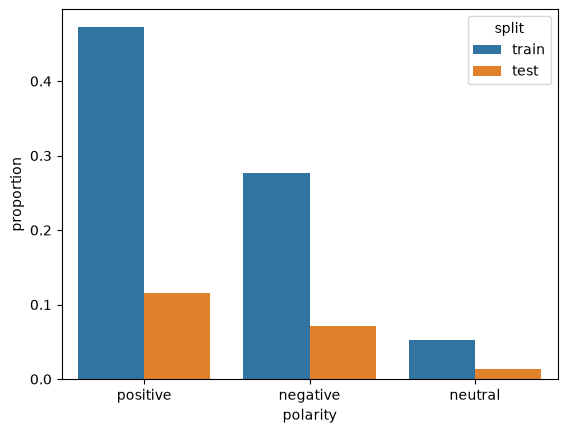

In [23]:
sns.countplot(data=ops, x="polarity", hue="split", stat="proportion");

In [24]:
pols = ops.groupby("sentence_id").polarity.agg(set)
print(pols.map(lambda p: {"positive", "negative"} <= p).sum(), "sentences with both positive and negative")

460 sentences with both positive and negative


In [25]:
tr = sents[sents.split == "train"]
print(tr.text.duplicated().sum(), "duplicate sentences in train")
print(len(set(tr.text) & set(sents[sents.split == "test"].text)), "texts shared between train and test")

labels = ops.groupby("sentence_id").apply(lambda g: frozenset(zip(g.category, g.polarity)))
tr = tr.assign(labels=tr.sentence_id.map(labels).apply(lambda x: x if isinstance(x, frozenset) else frozenset()))
print((tr.groupby("text").labels.nunique() > 1).sum(), "texts with contradictory labels")

14 duplicate sentences in train
5 texts shared between train and test
3 texts with contradictory labels


In [26]:
CLEAN_DATA = notebook_dir.parent / "data" / "clean"
CLEAN_DATA.mkdir(parents=True, exist_ok=True)

df[df.split == "train"].drop(columns="split").to_csv(CLEAN_DATA / "hotels_absa_train.csv", index=False)